<a href="https://colab.research.google.com/github/kmetz-erau/heatscreener/blob/main/campus_heat_screening_revised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
"""Campus-wide extreme-heat risk screening.

This Colab workflow combines:
  * Landsat surface-temperature observations during the warm season;
  * a campus-wide analysis grid rather than building footprints alone;
  * optional exposure, sensitivity, shade, vegetation, and cooling attributes;
  * quality/confidence flags and a transparent composite risk score.

This is a screening tool. It is not a substitute for on-site air-temperature,
shade, HVAC, health, or occupational-safety assessments.
"""

!pip -q install geopandas planetary-computer pystac-client rasterio shapely matplotlib pandas numpy

import io
import warnings
from contextlib import nullcontext

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pystac_client
import rasterio
from google.colab import files
from rasterio.features import geometry_mask
from rasterio.mask import mask
from rasterio.transform import from_origin
from shapely.geometry import box, mapping

warnings.filterwarnings('ignore', category=RuntimeWarning)

print('Imports complete.')



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 3.3 MB/s eta 0:00:00
Imports complete.


In [ ]:
# 1. Upload campus buildings and establish a projected campus analysis area.


### Input data

Upload a GeoJSON of campus building footprints. Optional numeric fields can improve the risk score: `occupancy_score`, `sensitivity_score`, `protection_score`, `shade_score`, and `cooling_access_score`, each on a 0–100 scale. Missing fields receive neutral assumptions and are reported in the output.


In [2]:
uploaded = files.upload()
if not uploaded:
    raise ValueError('No campus GeoJSON was uploaded.')

filename, contents = next(iter(uploaded.items()))
buildings = gpd.read_file(io.BytesIO(contents))
if buildings.empty:
    raise ValueError('The GeoJSON contains no features.')
if buildings.crs is None:
    buildings = buildings.set_crs('EPSG:4326')

buildings = buildings.to_crs('EPSG:26912')  # NAD83 / UTM zone 12N: Prescott
buildings = buildings[buildings.geometry.notna() & ~buildings.geometry.is_empty].copy()
buildings['geometry'] = buildings.geometry.make_valid()

if 'building_id' not in buildings.columns:
    if 'id' in buildings.columns:
        buildings['building_id'] = buildings['id'].astype(str)
    elif 'name' in buildings.columns:
        buildings['building_id'] = buildings['name'].astype(str)
    else:
        buildings['building_id'] = [f'building_{i + 1}' for i in range(len(buildings))]

print(f'Loaded {len(buildings)} building footprints from {filename}.')



Saving PR_buildings (1).geojson to PR_buildings (1).geojson
Loaded 85 building footprints from PR_buildings (1).geojson.


In [ ]:
# 2. Screening settings.


### Risk interpretation

The composite score combines heat hazard, exposure, sensitivity, and lack of protection. Review `confidence` before acting on any individual cell or building.


In [3]:
grid_cell_m = 100
campus_buffer_m = 150
start_date = '2019-05-01'
end_date = '2026-09-30'
max_cloud_cover = 50
max_scenes = 24
min_valid_pixels_per_cell = 2

# Scoring weights. All component scores are 0-100.
HAZARD_WEIGHT = 0.50
EXPOSURE_WEIGHT = 0.20
SENSITIVITY_WEIGHT = 0.15
PROTECTION_WEIGHT = 0.15

# Optional numeric GeoJSON fields. If absent, the script uses transparent
# neutral assumptions and records that fact in the outputs.
OPTIONAL_FIELDS = {
    'occupancy_score': 50.0,
    'sensitivity_score': 50.0,
    'protection_score': 50.0,
    'shade_score': 50.0,
    'cooling_access_score': 50.0,
}

for field, default in OPTIONAL_FIELDS.items():
    if field not in buildings.columns:
        buildings[field] = default
        print(f'Assumption: {field} not supplied; using {default:.0f} for all buildings.')
    else:
        buildings[field] = pd.to_numeric(buildings[field], errors='coerce').fillna(default).clip(0, 100)

campus_area = buildings.unary_union.buffer(campus_buffer_m)
min_x, min_y, max_x, max_y = campus_area.bounds
min_x = np.floor(min_x / grid_cell_m) * grid_cell_m
min_y = np.floor(min_y / grid_cell_m) * grid_cell_m
max_x = np.ceil(max_x / grid_cell_m) * grid_cell_m
max_y = np.ceil(max_y / grid_cell_m) * grid_cell_m

grid_records = []
cell_id = 1
y = min_y
while y < max_y:
    x = min_x
    while x < max_x:
        cell = box(x, y, x + grid_cell_m, y + grid_cell_m)
        if cell.intersects(campus_area):
            grid_records.append({'cell_id': f'cell_{cell_id:04d}', 'geometry': cell})
            cell_id += 1
        x += grid_cell_m
    y += grid_cell_m

grid = gpd.GeoDataFrame(grid_records, crs=buildings.crs)
if grid.empty:
    raise ValueError('The campus grid is empty. Check the uploaded building geometries.')

# Transfer building attributes to grid cells by area-weighted overlap.
grid['occupancy_score'] = 50.0
grid['sensitivity_score'] = 50.0
grid['protection_score'] = 50.0
grid['shade_score'] = 50.0
grid['cooling_access_score'] = 50.0
for idx, cell in grid.iterrows():
    overlaps = buildings[buildings.geometry.intersects(cell.geometry)]
    if len(overlaps):
        weights = overlaps.geometry.intersection(cell.geometry).area
        weights = weights / weights.sum() if weights.sum() else np.ones(len(overlaps)) / len(overlaps)
        for field in OPTIONAL_FIELDS:
            grid.at[idx, field] = float(np.average(overlaps[field], weights=weights))

print(f'Created {len(grid)} campus analysis cells at {grid_cell_m} m resolution.')



Assumption: occupancy_score not supplied; using 50 for all buildings.
Assumption: sensitivity_score not supplied; using 50 for all buildings.
Assumption: protection_score not supplied; using 50 for all buildings.
Assumption: shade_score not supplied; using 50 for all buildings.
Assumption: cooling_access_score not supplied; using 50 for all buildings.


/tmp/ipykernel_1645/1627264290.py:32: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  campus_area = buildings.unary_union.buffer(campus_buffer_m)


Created 174 campus analysis cells at 100 m resolution.


In [4]:
# 3. Search for warm-season Landsat scenes over the actual campus extent.


In [5]:
campus_wgs84 = gpd.GeoSeries([campus_area], crs=buildings.crs).to_crs('EPSG:4326').iloc[0]
min_lon, min_lat, max_lon, max_lat = campus_wgs84.bounds

if not (-180 <= min_lon < max_lon <= 180 and -90 <= min_lat < max_lat <= 90):
    raise ValueError('Campus bounding-box coordinates are invalid.')

catalog = pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1')
search = catalog.search(
    collections=['landsat-c2-l2'],
    bbox=[min_lon, min_lat, max_lon, max_lat],
    datetime=f'{start_date}/{end_date}',
    query={'eo:cloud_cover': {'lt': max_cloud_cover}},
)

all_items = list(search.item_collection())
items = sorted(
    [item for item in all_items if 5 <= pd.Timestamp(item.datetime or item.properties.get('datetime')).month <= 9],
    key=lambda item: pd.Timestamp(item.datetime or item.properties.get('datetime')),
    reverse=True,
)[:max_scenes]

print(f'Found {len(items)} warm-season Landsat scenes.')
if not items:
    raise ValueError('No warm-season scenes matched the campus, dates, and cloud threshold.')



Found 24 warm-season Landsat scenes.


In [ ]:
# 4. Extract surface temperature by campus cell with QA and confidence data.


In [6]:
records = []
scene_errors = []

for item in items:
    assets = item.assets
    thermal_key = 'lwir11' if 'lwir11' in assets else 'lwir' if 'lwir' in assets else None
    if thermal_key is None:
        continue

    thermal_href = planetary_computer.sign(assets[thermal_key].href)
    qa_href = None
    for candidate in ('qa_pixel', 'qa'):
        if candidate in assets:
            qa_href = planetary_computer.sign(assets[candidate].href)
            break

    scene_date = pd.Timestamp(item.datetime or item.properties.get('datetime')).date().isoformat()

    try:
        with rasterio.open(thermal_href) as thermal_src:
            scene_grid = grid.to_crs(thermal_src.crs)
            with rasterio.open(qa_href) if qa_href else nullcontext() as qa_src:
                for _, row in scene_grid.iterrows():
                    try:
                        geom = [mapping(row.geometry)]
                        thermal_arr, _ = mask(thermal_src, geom, crop=True, filled=False)
                        raw = thermal_arr[0].astype('float32').filled(np.nan)
                        valid = np.isfinite(raw)

                        # Landsat Collection 2 Level-2 ST scale/offset.
                        temp_c = raw * 0.00341802 + 149.0 - 273.15

                        if qa_src:
                            qa_arr, _ = mask(qa_src, geom, crop=True, filled=False)
                            qa = qa_arr[0].filled(1).astype('uint16')
                            if qa.shape == valid.shape:
                                # QA_PIXEL: fill, dilated cloud, cirrus, cloud,
                                # cloud shadow, and snow.
                                bad = (
                                    ((qa & 1) != 0) |
                                    ((qa & 2) != 0) |
                                    ((qa & 4) != 0) |
                                    ((qa & 8) != 0) |
                                    ((qa & 16) != 0) |
                                    ((qa & 32) != 0)
                                )
                                valid &= ~bad

                        values = temp_c[valid]
                        values = values[np.isfinite(values)]
                        if len(values) >= min_valid_pixels_per_cell:
                            records.append({
                                'cell_id': row['cell_id'],
                                'scene_date': scene_date,
                                'scene_cloud_pct': item.properties.get('eo:cloud_cover'),
                                'pixel_count': int(len(values)),
                                'mean_surface_temp_c': float(np.mean(values)),
                                'median_surface_temp_c': float(np.median(values)),
                                'p90_surface_temp_c': float(np.percentile(values, 90)),
                                'max_surface_temp_c': float(np.max(values)),
                            })
                    except Exception as exc:
                        scene_errors.append(f'{scene_date}/{row["cell_id"]}: {exc}')
    except Exception as exc:
        scene_errors.append(f'{scene_date}: {exc}')

if not records:
    raise ValueError('No valid thermal pixels intersected the campus grid.')

observations = pd.DataFrame(records)



In [ ]:
# 5. Convert observations into robust hazard indicators.


In [7]:
grid_summary = (
    observations.groupby('cell_id', as_index=False)
    .agg(
        scenes=('scene_date', 'nunique'),
        mean_surface_temp_c=('mean_surface_temp_c', 'mean'),
        summer_median_temp_c=('median_surface_temp_c', 'median'),
        summer_p90_temp_c=('p90_surface_temp_c', lambda s: np.percentile(s, 90)),
        warmest_observation_c=('max_surface_temp_c', 'max'),
        total_valid_pixels=('pixel_count', 'sum'),
    )
)

grid_summary = grid_summary.rename(columns={'summer_p90_temp_c': 'summer_p90_temp_c'})
grid_summary['heat_hazard_score'] = (
    100 * (grid_summary['summer_p90_temp_c'] - grid_summary['summer_p90_temp_c'].min()) /
    max(grid_summary['summer_p90_temp_c'].max() - grid_summary['summer_p90_temp_c'].min(), 0.01)
).clip(0, 100)

grid_summary['coverage_score'] = (
    100 * grid_summary['scenes'] / max(len(items), 1)
).clip(0, 100)
grid_summary['pixel_confidence'] = pd.cut(
    grid_summary['total_valid_pixels'],
    bins=[-np.inf, 4, 19, np.inf],
    labels=['low', 'medium', 'high'],
)
grid_summary['confidence'] = np.where(
    grid_summary['coverage_score'] < 25,
    'low',
    grid_summary['pixel_confidence'].astype(str),
)

grid = grid.merge(grid_summary, on='cell_id', how='left')



In [ ]:
# 6. Build a transparent composite risk score.


In [8]:
grid['exposure_score'] = grid['occupancy_score']
grid['protection_score'] = (
    0.50 * grid['protection_score'] +
    0.25 * grid['shade_score'] +
    0.25 * grid['cooling_access_score']
).clip(0, 100)

grid['overall_heat_risk_score'] = (
    HAZARD_WEIGHT * grid['heat_hazard_score'] +
    EXPOSURE_WEIGHT * grid['exposure_score'] +
    SENSITIVITY_WEIGHT * grid['sensitivity_score'] +
    PROTECTION_WEIGHT * (100 - grid['protection_score'])
).clip(0, 100)

grid['risk_class'] = pd.cut(
    grid['overall_heat_risk_score'],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=['low', 'moderate', 'high', 'very high'],
)
grid['recommended_action'] = np.select(
    [
        grid['overall_heat_risk_score'] >= 75,
        grid['overall_heat_risk_score'] >= 50,
        grid['overall_heat_risk_score'] >= 25,
    ],
    [
        'Prioritize shade/cooling intervention and field verification',
        'Investigate shade, occupancy, and cooling access',
        'Monitor and address during heat advisories',
    ],
    default='Routine monitoring',
)

# Summarize building-level risk by assigning each building its intersecting grid cells.
building_cells = gpd.sjoin(
    buildings[['building_id', 'geometry']],
    grid[['cell_id', 'geometry']],
    predicate='intersects',
    how='left',
).drop(columns=['index_right'], errors='ignore')

building_summary = (
    building_cells.merge(
        grid.drop(columns='geometry'), on='cell_id', how='left'
    )
    .groupby('building_id', as_index=False)
    .agg(
        cells=('cell_id', 'nunique'),
        summer_p90_temp_c=('summer_p90_temp_c', 'mean'),
        warmest_observation_c=('warmest_observation_c', 'max'),
        heat_hazard_score=('heat_hazard_score', 'mean'),
        overall_heat_risk_score=('overall_heat_risk_score', 'mean'),
        confidence=('confidence', lambda s: 'low' if 'low' in set(s.astype(str)) else 'medium'),
    )
)
building_summary['risk_class'] = pd.cut(
    building_summary['overall_heat_risk_score'],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=['low', 'moderate', 'high', 'very high'],
)



In [ ]:
# 7. Export ranked GIS/CSV outputs and a campus risk map.


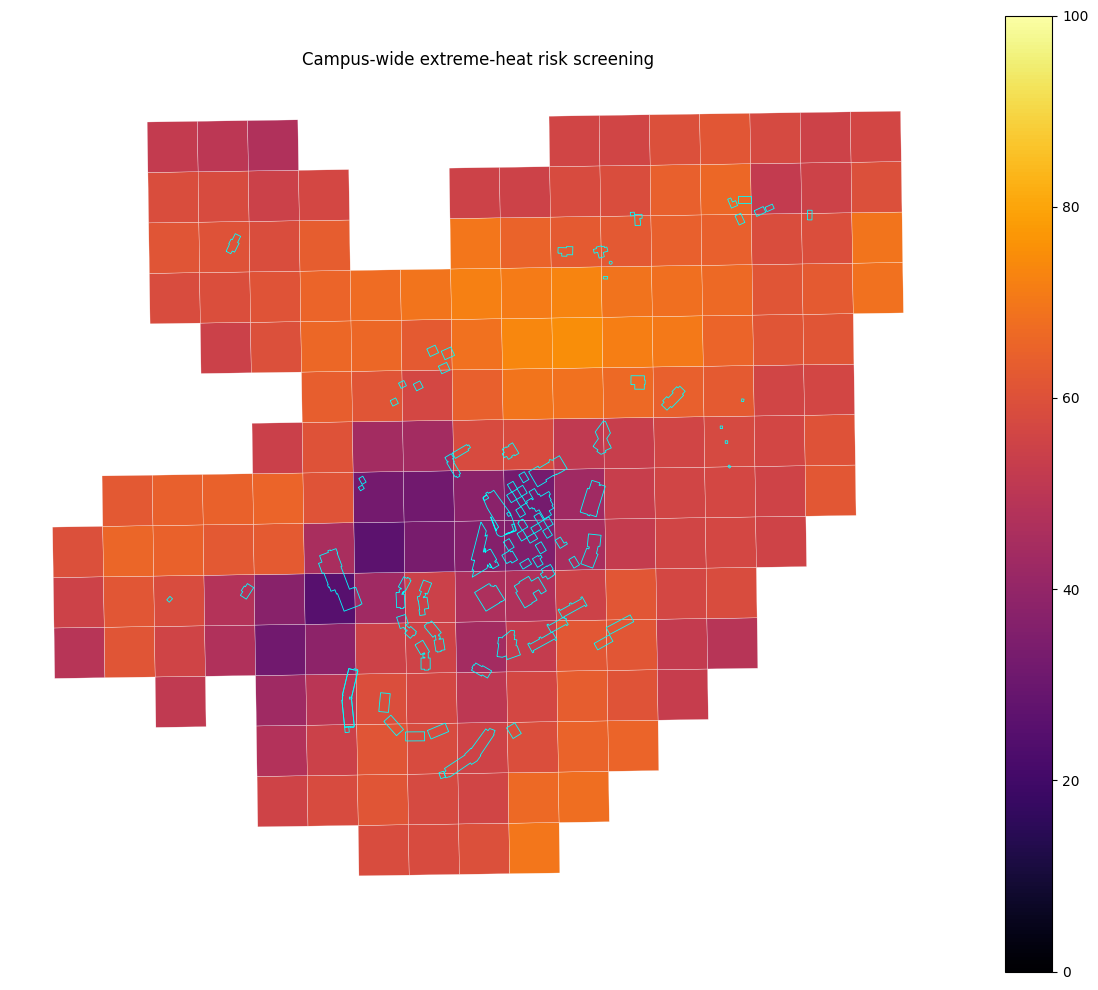

Processed 24 warm-season scenes and 174 campus cells.
Created 85 building summaries.
Outputs:
  campus_heat_risk_grid.geojson
  campus_heat_risk_grid.csv
  campus_building_heat_risk.geojson
  campus_building_heat_risk.csv
  campus_heat_risk_map.png


In [9]:
grid_out = grid.to_crs('EPSG:4326')
building_out = buildings.merge(building_summary, on='building_id', how='left').to_crs('EPSG:4326')

grid_out.to_file('campus_heat_risk_grid.geojson', driver='GeoJSON')
building_out.to_file('campus_building_heat_risk.geojson', driver='GeoJSON')
grid.drop(columns='geometry').sort_values('overall_heat_risk_score', ascending=False).to_csv(
    'campus_heat_risk_grid.csv', index=False
)
building_summary.sort_values('overall_heat_risk_score', ascending=False).to_csv(
    'campus_building_heat_risk.csv', index=False
)

fig, ax = plt.subplots(figsize=(12, 10))
grid_out.plot(
    ax=ax,
    column='overall_heat_risk_score',
    cmap='inferno',
    vmin=0,
    vmax=100,
    legend=True,
    edgecolor='white',
    linewidth=0.2,
    missing_kwds={'color': 'lightgray', 'label': 'No valid thermal data'},
)
buildings.to_crs('EPSG:4326').boundary.plot(ax=ax, color='cyan', linewidth=0.6)
ax.set_title('Campus-wide extreme-heat risk screening')
ax.set_axis_off()
plt.tight_layout()
plt.savefig('campus_heat_risk_map.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Processed {len(items)} warm-season scenes and {len(grid)} campus cells.')
print(f'Created {len(building_summary)} building summaries.')
print('Outputs:')
print('  campus_heat_risk_grid.geojson')
print('  campus_heat_risk_grid.csv')
print('  campus_building_heat_risk.geojson')
print('  campus_building_heat_risk.csv')
print('  campus_heat_risk_map.png')
if scene_errors:
    print(f'Warnings: {len(scene_errors)} scene/cell operations were skipped.')
